# Video Game Sales Prediction Using Historical Game and Review Data

**Goal:** predict `Global_Sales` (in millions) using historical game metadata and review information.

This notebook is organized from data loading through cleaning, EDA, feature preparation, model training, evaluation, and interpretation. **Preprocessing is performed manually** with Pandas; this notebook does not use `Pipeline` or `ColumnTransformer`.


### 1.1 Import libraries

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


### 1.2 Load the dataset

In [4]:
DATA_PATH = Path("C:\\Users\\User\\Downloads\\Video Game Sales dataset\\Video_Games_Sales_as_at_22_Dec_2016.csv")
if not DATA_PATH.exists():
    candidates = list(Path.cwd().glob("*.csv"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            "CSV not found. Put Video_Games_Sales_as_at_22_Dec_2016.csv "
            "beside this notebook or set DATA_PATH to its location."
        )

df = pd.read_csv(DATA_PATH)
print("Loaded file:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())


Loaded file: C:\Users\User\Downloads\Video Game Sales dataset\Video_Games_Sales_as_at_22_Dec_2016.csv
Shape: (16719, 16)


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Initial data inspection

### 2.1 Dataset dimensions and columns

In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (16719, 16)

Column names:
['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating']


### 2.2 Data types and summary statistics

In [6]:
print("Data types and non-null counts:")
df.info()
print("\nNumerical and categorical summary:")
display(df.describe(include="all").T)


Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       7590 non-null   float64
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(10), str(6)
memory usage: 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,16717,11562,Need for Speed: Most Wanted,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,16719,31,PS2,2161,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year_of_Release,16450.0,NaN,NaN,NaN,2006.487356,5.878995,1980.0,2003.0,2007.0,2010.0,2020.0
Genre,16717,12,Action,3370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Publisher,16665,582,Electronic Arts,1356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NA_Sales,16719.0,NaN,NaN,NaN,0.26333,0.813514,0.0,0.0,0.08,0.24,41.36
EU_Sales,16719.0,NaN,NaN,NaN,0.145025,0.503283,0.0,0.0,0.02,0.11,28.96
JP_Sales,16719.0,NaN,NaN,NaN,0.077602,0.308818,0.0,0.0,0.0,0.04,10.22
Other_Sales,16719.0,NaN,NaN,NaN,0.047332,0.18671,0.0,0.0,0.01,0.03,10.57
Global_Sales,16719.0,NaN,NaN,NaN,0.533543,1.547935,0.01,0.06,0.17,0.47,82.53


### 2.3 Missing values and duplicates

In [7]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)
display(missing_summary[missing_summary["Missing_Count"] > 0])
print("Duplicate rows:", df.duplicated().sum())


,Missing_Count,Missing_Percentage
User_Score,9129,54.60
User_Count,9129,54.60
Critic_Score,8582,51.33
Critic_Count,8582,51.33
Rating,6769,40.49
Developer,6623,39.61
Year_of_Release,269,1.61
Publisher,54,0.32
Name,2,0.01
Genre,2,0.01


Duplicate rows: 0


## 3. Data cleaning and validation

- Remove exact duplicate rows.
- Convert score, count, year, and sales columns to numeric values.
- Values such as `tbd` in `User_Score` become missing values.
- Drop rows with a missing target (`Global_Sales`) or game name.
- Keep missing feature values for imputation after the train-test split.
- Do not remove high-sales outliers automatically: blockbuster sales may be legitimate.

### 3.1 Remove duplicate records

In [8]:
df = df.copy()
duplicate_count = int(df.duplicated().sum())
if duplicate_count:
    df = df.drop_duplicates().copy()
print("Duplicate rows removed:", duplicate_count)
print("Shape after duplicate removal:", df.shape)


Duplicate rows removed: 0
Shape after duplicate removal: (16719, 16)


### 3.2 Convert numeric columns

In [9]:
numeric_candidates = [
    "Year_of_Release", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales",
    "Global_Sales", "Critic_Score", "Critic_Count", "User_Score", "User_Count"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_candidates].dtypes)


Year_of_Release    float64
NA_Sales           float64
EU_Sales           float64
JP_Sales           float64
Other_Sales        float64
Global_Sales       float64
Critic_Score       float64
Critic_Count       float64
User_Score         float64
User_Count         float64
dtype: object


### 3.3 Clean categorical text columns

In [10]:
categorical_candidates = ["Name", "Platform", "Genre", "Publisher", "Developer", "Rating"]
for col in categorical_candidates:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace("", pd.NA)

print("Categorical columns cleaned:", [c for c in categorical_candidates if c in df.columns])


Categorical columns cleaned: ['Name', 'Platform', 'Genre', 'Publisher', 'Developer', 'Rating']


### 3.4 Remove rows without target or game name

In [11]:
if "Global_Sales" not in df.columns:
    raise KeyError("Expected target column 'Global_Sales' was not found.")

before = len(df)
df = df.dropna(subset=["Global_Sales"]).copy()
if "Name" in df.columns:
    df = df.dropna(subset=["Name"]).copy()
print("Rows removed for missing target/name:", before - len(df))
print("Shape after cleaning:", df.shape)
display(df.isna().sum().to_frame("Missing_Count"))


Rows removed for missing target/name: 2
Shape after cleaning: (16717, 16)


,Missing_Count
Name,0
Platform,0
Year_of_Release,269
Genre,0
Publisher,54
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0
Global_Sales,0


## 4. Exploratory data analysis (EDA)

### 4.1 Numeric distributions

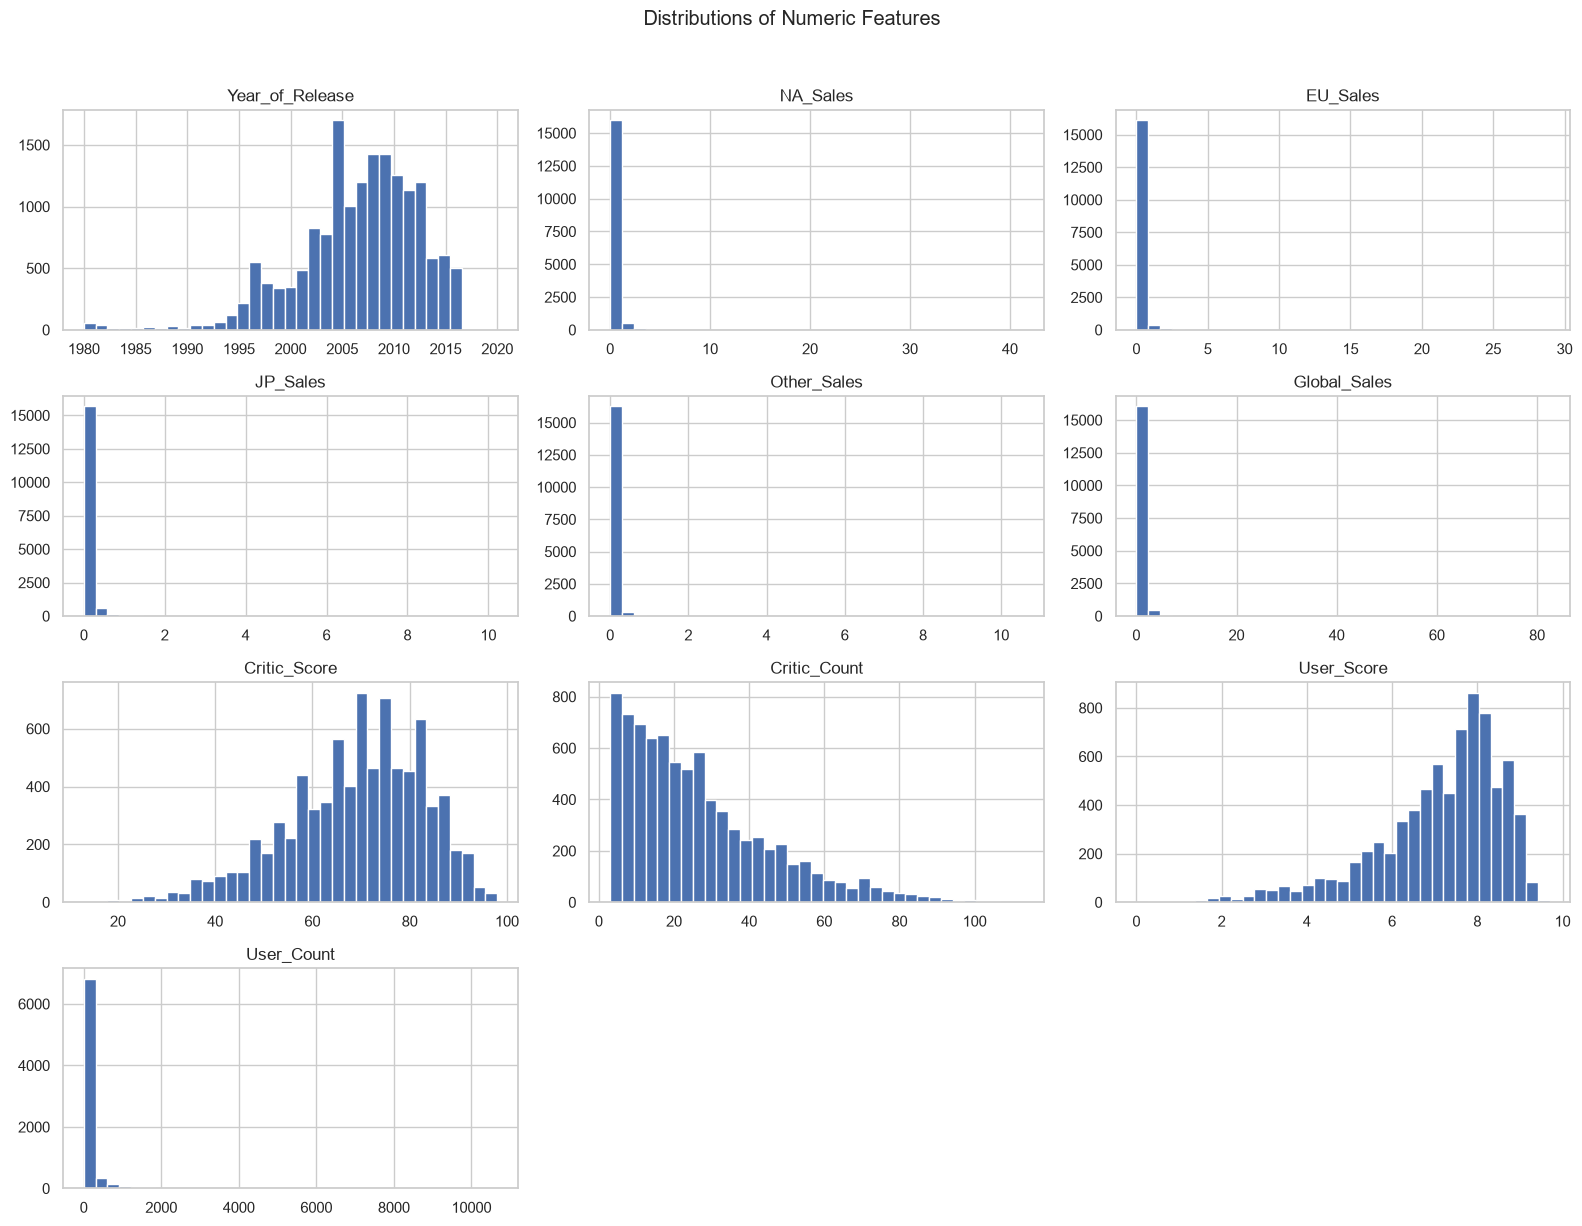

In [12]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(16, 12), bins=35)
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()


### 4.2 Global sales distribution

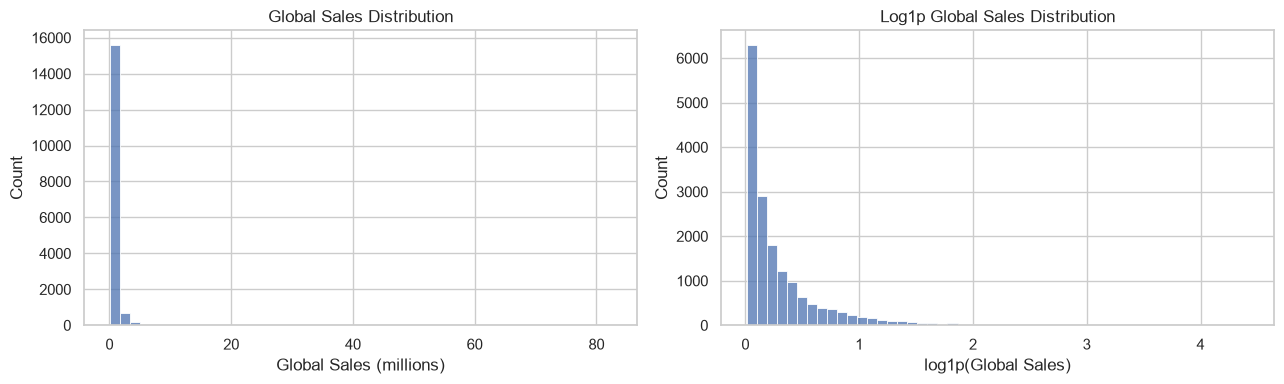

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Global_Sales"], bins=50, ax=axes[0])
axes[0].set_title("Global Sales Distribution")
axes[0].set_xlabel("Global Sales (millions)")
sns.histplot(np.log1p(df["Global_Sales"].clip(lower=0)), bins=50, ax=axes[1])
axes[1].set_title("Log1p Global Sales Distribution")
axes[1].set_xlabel("log1p(Global Sales)")
plt.tight_layout()
plt.show()


### 4.3 Top-selling games

In [14]:
show_cols = [c for c in ["Name", "Platform", "Year_of_Release", "Genre", "Global_Sales"] if c in df.columns]
display(df.nlargest(10, "Global_Sales")[show_cols])


,Name,Platform,Year_of_Release,Genre,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,82.53
1,Super Mario Bros.,NES,1985.0,Platform,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,35.52
3,Wii Sports Resort,Wii,2009.0,Sports,32.77
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,31.37
5,Tetris,GB,1989.0,Puzzle,30.26
6,New Super Mario Bros.,DS,2006.0,Platform,29.80
7,Wii Play,Wii,2006.0,Misc,28.92
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,28.32
9,Duck Hunt,NES,1984.0,Shooter,28.31


### 4.4 Platform and genre game counts

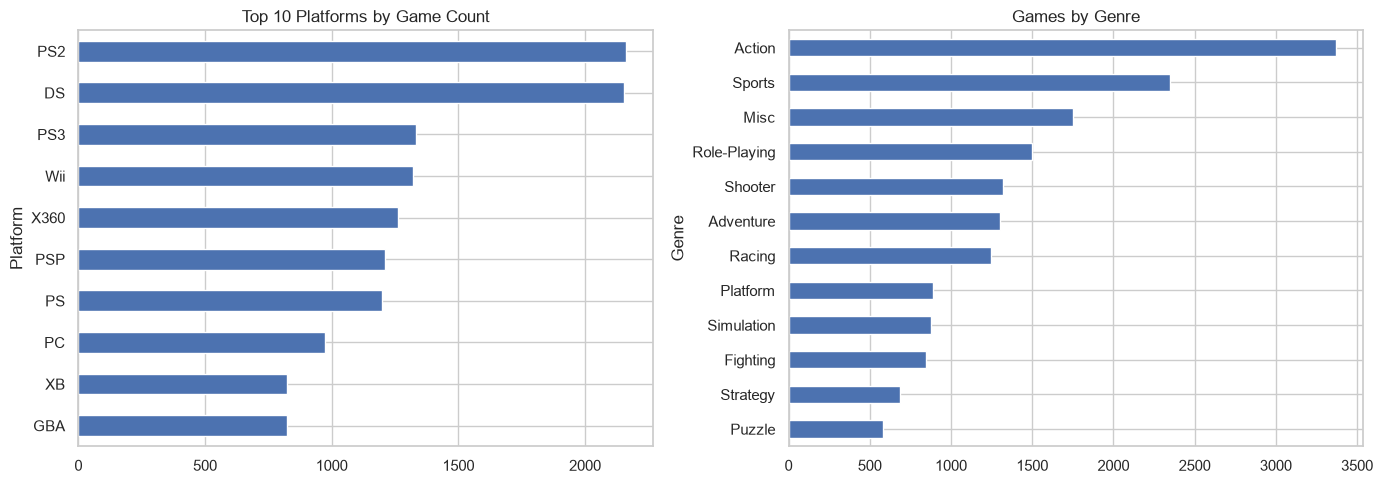

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
if "Platform" in df.columns:
    df["Platform"].value_counts().head(10).sort_values().plot(kind="barh", ax=axes[0])
    axes[0].set_title("Top 10 Platforms by Game Count")
if "Genre" in df.columns:
    df["Genre"].value_counts().sort_values().plot(kind="barh", ax=axes[1])
    axes[1].set_title("Games by Genre")
plt.tight_layout()
plt.show()


### 4.5 Average global sales by genre

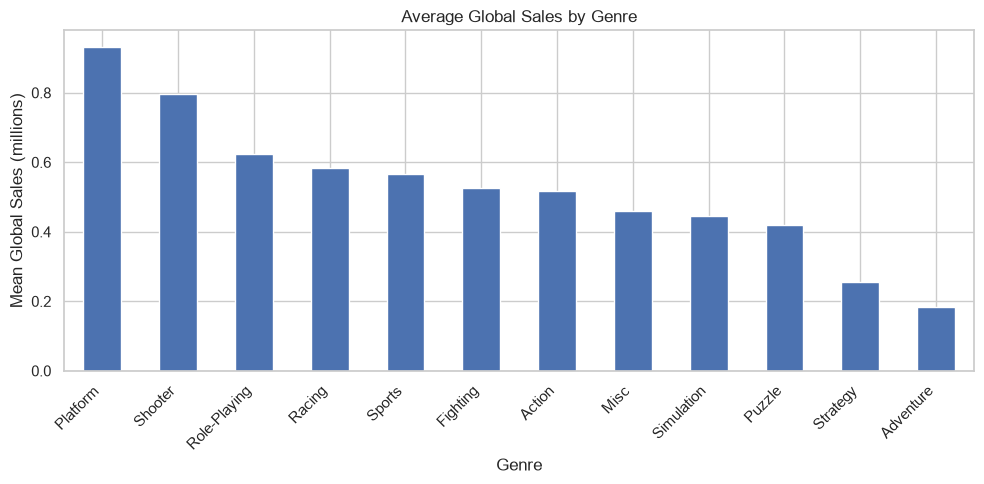

In [16]:
if "Genre" in df.columns:
    genre_sales = df.groupby("Genre", dropna=False)["Global_Sales"].mean().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    genre_sales.plot(kind="bar")
    plt.title("Average Global Sales by Genre")
    plt.ylabel("Mean Global Sales (millions)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


### 4.6 Average global sales by platform

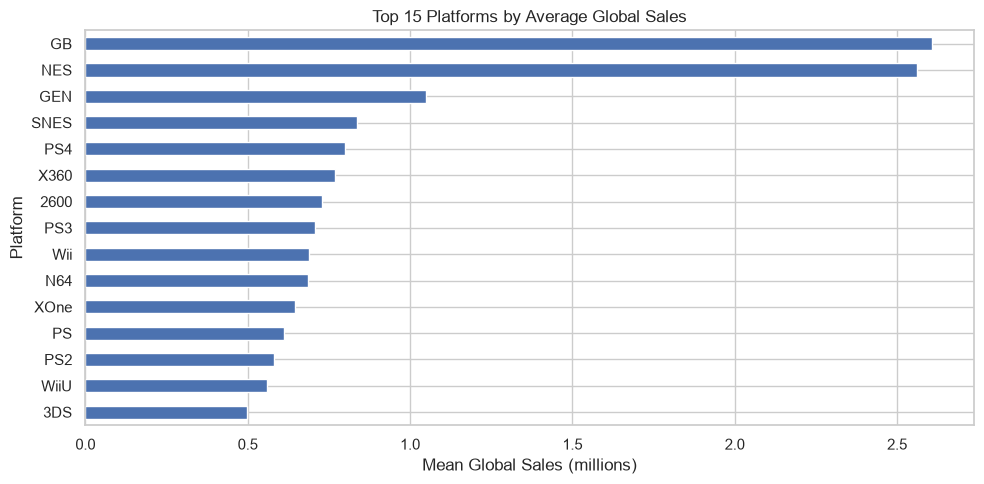

In [17]:
if "Platform" in df.columns:
    platform_sales = df.groupby("Platform")["Global_Sales"].mean().sort_values(ascending=False).head(15)
    plt.figure(figsize=(10, 5))
    platform_sales.sort_values().plot(kind="barh")
    plt.title("Top 15 Platforms by Average Global Sales")
    plt.xlabel("Mean Global Sales (millions)")
    plt.tight_layout()
    plt.show()


### 4.7 Correlation analysis

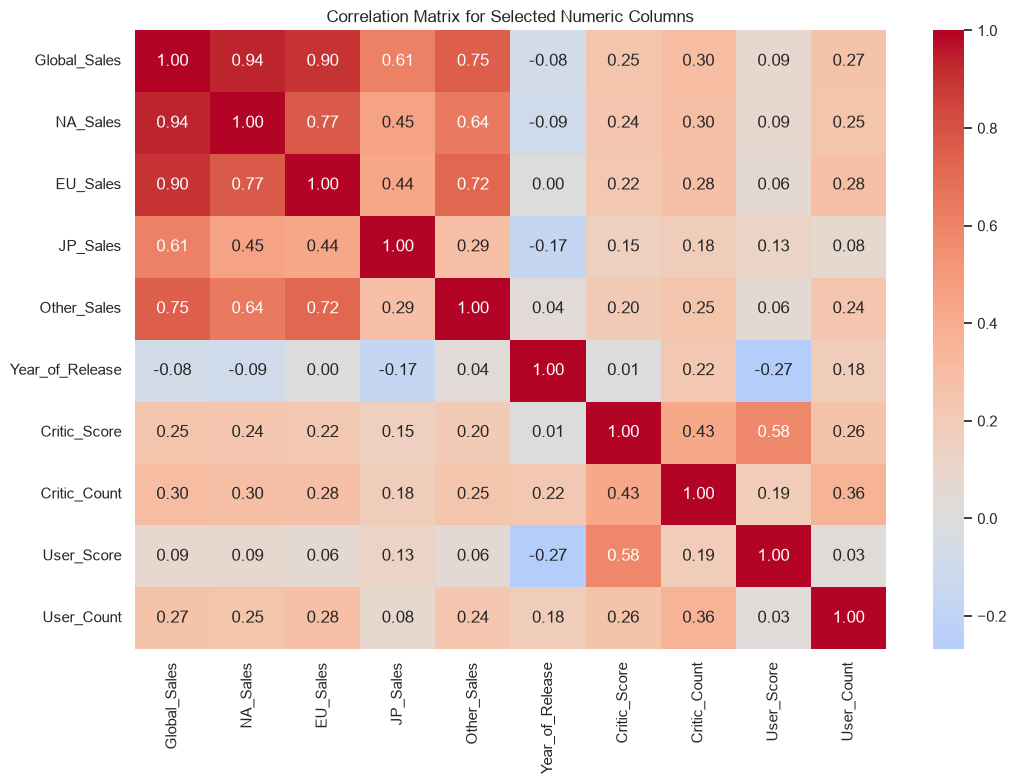

In [18]:
corr_cols = [c for c in ["Global_Sales", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Year_of_Release", "Critic_Score", "Critic_Count", "User_Score", "User_Count"] if c in df.columns]
plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix for Selected Numeric Columns")
plt.tight_layout()
plt.show()


### 4.8 Investigate extreme values (do not automatically remove them)

In [19]:
print("Highest global sales:")
display(df.nlargest(10, "Global_Sales")[show_cols])
for col in ["Global_Sales", "Critic_Score", "Critic_Count", "User_Count"]:
    if col in df.columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        n = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
        print(f"{col}: {n} observations outside the 1.5*IQR range")


Highest global sales:


,Name,Platform,Year_of_Release,Genre,Global_Sales
0,Wii Sports,Wii,2006.0,Sports,82.53
1,Super Mario Bros.,NES,1985.0,Platform,40.24
2,Mario Kart Wii,Wii,2008.0,Racing,35.52
3,Wii Sports Resort,Wii,2009.0,Sports,32.77
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,31.37
5,Tetris,GB,1989.0,Puzzle,30.26
6,New Super Mario Bros.,DS,2006.0,Platform,29.80
7,Wii Play,Wii,2006.0,Misc,28.92
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,28.32
9,Duck Hunt,NES,1984.0,Shooter,28.31


Global_Sales: 1891 observations outside the 1.5*IQR range
Critic_Score: 83 observations outside the 1.5*IQR range
Critic_Count: 251 observations outside the 1.5*IQR range
User_Count: 1080 observations outside the 1.5*IQR range


## 5. Define features and target

`Global_Sales` is the target. Regional sales (`NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`) are intentionally excluded because they are components of global sales and would leak the target. This setup is more appropriate when predicting sales from game metadata and review data. If the intended use case is after regional sales are already known, define that different prediction task explicitly.

### 5.1 Choose categorical and numerical features

In [20]:
categorical_features = [c for c in ["Platform", "Genre", "Publisher", "Developer", "Rating"] if c in df.columns]
numerical_features = [c for c in ["Year_of_Release", "Critic_Score", "Critic_Count", "User_Score", "User_Count"] if c in df.columns]
feature_columns = categorical_features + numerical_features

if not feature_columns:
    raise ValueError("No expected feature columns were found. Check the dataset column names.")

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


Categorical features: ['Platform', 'Genre', 'Publisher', 'Developer', 'Rating']
Numerical features: ['Year_of_Release', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']


### 5.2 Define X and y

In [21]:
X = df[feature_columns].copy()
y = df["Global_Sales"].copy()
print("X shape:", X.shape, "| y shape:", y.shape)
display(X.head())


X shape: (16717, 10) | y shape: (16717,)


,Platform,Genre,Publisher,Developer,Rating,Year_of_Release,Critic_Score,Critic_Count,User_Score,User_Count
0,Wii,Sports,Nintendo,Nintendo,E,2006.0,76.0,51.0,8.0,322.0
1,NES,Platform,Nintendo,<NA>,<NA>,1985.0,NaN,NaN,NaN,NaN
2,Wii,Racing,Nintendo,Nintendo,E,2008.0,82.0,73.0,8.3,709.0
3,Wii,Sports,Nintendo,Nintendo,E,2009.0,80.0,73.0,8.0,192.0
4,GB,Role-Playing,Nintendo,<NA>,<NA>,1996.0,NaN,NaN,NaN,NaN


## 6. Train-test split

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 13373
Testing rows: 3344


## 7. Manual preprocessing (no Pipeline)

Imputation values are learned from the training set only. Missing categories are represented as `Unknown`. One-hot encoding is performed with `pandas.get_dummies`, and the test columns are aligned to the training columns.

### 7.1 Fill numeric missing values using training medians

In [23]:
X_train = X_train.copy()
X_test = X_test.copy()

for col in numerical_features:
    median_value = X_train[col].median()
    if pd.isna(median_value):
        median_value = 0
    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

print("Numeric missing values in train:", int(X_train[numerical_features].isna().sum().sum()))
print("Numeric missing values in test:", int(X_test[numerical_features].isna().sum().sum()))


Numeric missing values in train: 0
Numeric missing values in test: 0


### 7.2 Fill missing categorical values

In [24]:
for col in categorical_features:
    X_train[col] = X_train[col].astype("object").where(X_train[col].notna(), "Unknown")
    X_test[col] = X_test[col].astype("object").where(X_test[col].notna(), "Unknown")

print("Categorical missing values in train:", int(X_train[categorical_features].isna().sum().sum()))
print("Categorical missing values in test:", int(X_test[categorical_features].isna().sum().sum()))


Categorical missing values in train: 0
Categorical missing values in test: 0


### 7.3 One-hot encode categorical features

In [25]:
X_train_encoded = pd.get_dummies(X_train, columns=categorical_features, dtype=int)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_features, dtype=int)
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape before alignment:", X_test_encoded.shape)


Encoded training shape: (13373, 2137)
Encoded testing shape before alignment: (3344, 1180)


### 7.4 Align training and testing columns

In [26]:
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape after alignment:", X_test_encoded.shape)
print("Missing values in encoded train:", int(X_train_encoded.isna().sum().sum()))
print("Missing values in encoded test:", int(X_test_encoded.isna().sum().sum()))
assert list(X_train_encoded.columns) == list(X_test_encoded.columns)


Encoded training shape: (13373, 2137)
Encoded testing shape after alignment: (3344, 2137)
Missing values in encoded train: 0
Missing values in encoded test: 0


## 8. Train regression models and evaluate

### 8.1 Define models

In [27]:
models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Decision Tree": DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1)
}

results = []
trained_models = {}
predictions_by_model = {}
print("Models:", list(models.keys()))


Models: ['Baseline', 'Decision Tree', 'Random Forest']


### 8.2 Train models and calculate metrics

In [28]:
for name, model in models.items():
    print("Training", name)
    model.fit(X_train_encoded, y_train)
    predictions = model.predict(X_test_encoded)
    predictions_by_model[name] = predictions
    trained_models[name] = model

    mse = mean_squared_error(y_test, predictions)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, predictions)
    })


Training Baseline
Training Decision Tree
Training Random Forest


### 8.3 Compare model results

In [29]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(results_df.round(4))
print("Best model by test RMSE:", results_df.loc[0, "Model"])


,Model,MAE,MSE,RMSE,R2
0,Decision Tree,0.4312,2.8563,1.6901,0.3084
1,Random Forest,0.3924,2.8704,1.6942,0.3049
2,Baseline,0.6137,4.1311,2.0325,-0.0003


Best model by test RMSE: Decision Tree


### 8.4 Compare RMSE

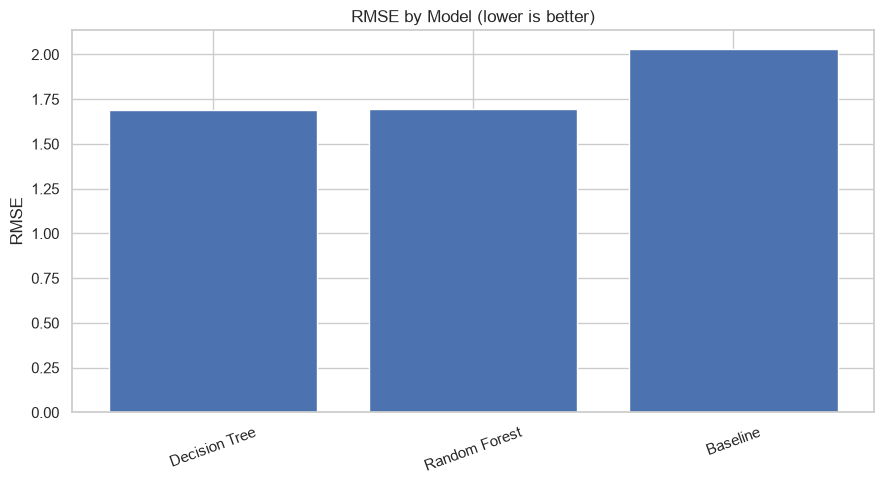

In [30]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("RMSE by Model (lower is better)")
plt.ylabel("RMSE")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### 8.5 Compare R²

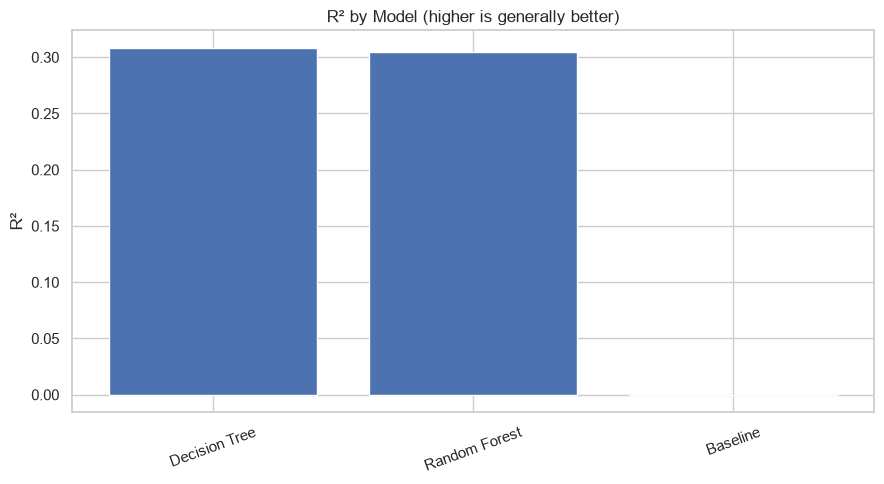

In [31]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("R² by Model (higher is generally better)")
plt.ylabel("R²")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 9. Actual versus predicted sales

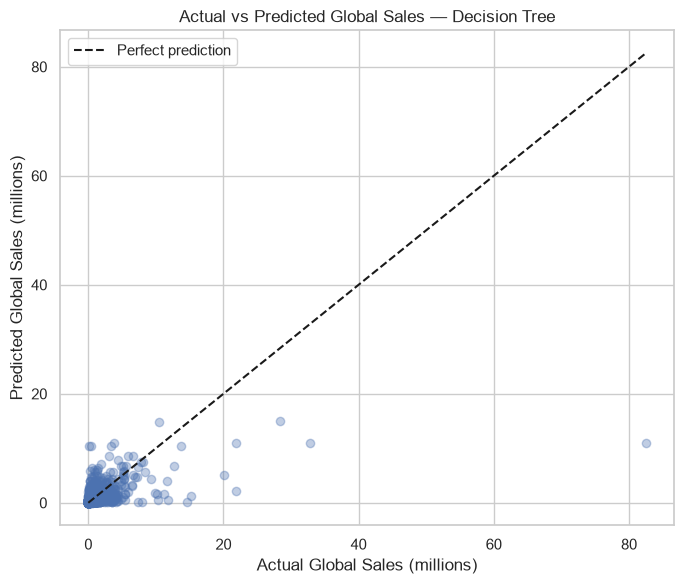

Best model: Decision Tree
MAE: 0.4312
RMSE: 1.6901
R²: 0.3084


In [32]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions_by_model[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.35)
upper = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([0, upper], [0, upper], "k--", label="Perfect prediction")
plt.xlabel("Actual Global Sales (millions)")
plt.ylabel("Predicted Global Sales (millions)")
plt.title(f"Actual vs Predicted Global Sales — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

print("Best model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 4))
print("R²:", round(r2_score(y_test, best_predictions), 4))

## 10. Feature importance

### 10.1 View Random Forest feature importance

In [33]:
rf_model = trained_models.get("Random Forest")
if rf_model is not None:
    importance_df = pd.DataFrame({
        "Feature": X_train_encoded.columns,
        "Importance": rf_model.feature_importances_
    }).sort_values("Importance", ascending=False).reset_index(drop=True)
    display(importance_df.head(20))
else:
    print("Random Forest was not trained; feature importance is unavailable.")


,Feature,Importance
0,User_Count,0.173302
1,Year_of_Release,0.171514
2,Publisher_Nintendo,0.078732
3,Critic_Score,0.065109
4,Platform_PC,0.053426
5,Developer_Nintendo,0.039233
6,Critic_Count,0.037632
7,Developer_Rockstar North,0.033507
8,User_Score,0.029179
9,Genre_Role-Playing,0.028152


### 10.2 Plot the top 15 features

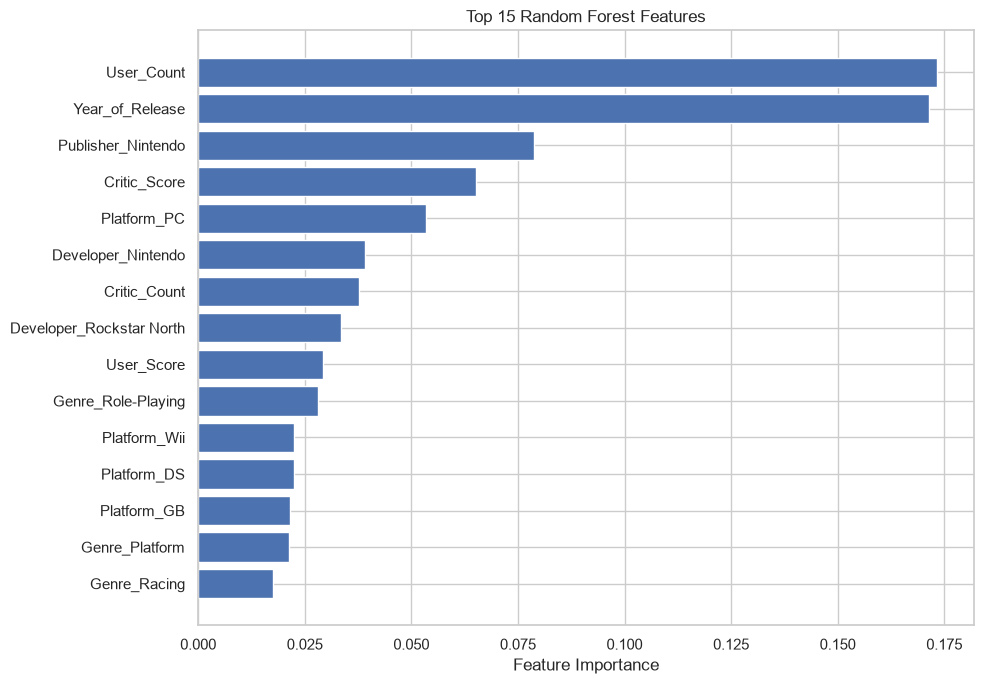

In [34]:
if rf_model is not None:
    top_features = importance_df.head(15).sort_values("Importance")
    plt.figure(figsize=(10, 7))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.xlabel("Feature Importance")
    plt.title("Top 15 Random Forest Features")
    plt.tight_layout()
    plt.show()
